In [0]:
file_path = "/Volumes/big_data/big_schema/big_volume/indian_banking_transactions.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

display(df)

transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
TXN000000001,CUST015796,2019-01-01,15:28:00,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,None,0.0,Success,Branch,Verified,0,15
TXN000000002,CUST000861,2019-01-01,03:00:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,None,0.0,Success,Mobile_App,Verified,0,3
TXN000000003,CUST076821,2019-01-01,18:03:00,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
TXN000000004,CUST054887,2019-01-01,08:03:00,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
TXN000000005,CUST006266,2019-01-01,14:23:00,Fixed Deposit,UPI,2573.8,Debit,26617.4,Utilities,West Bengal,767,0,None,0.0,Success,API,Verified,0,14
TXN000000006,CUST037195,2019-01-01,01:51:00,Fixed Deposit,Net_Banking,39172.48,Debit,1798.86,Government,Karnataka,707,1,Auto,4197.37,Pending,Web,Verified,0,1
TXN000000007,CUST044132,2019-01-01,06:27:00,Savings,NEFT,4008.09,Credit,177668.37,Investment,Punjab,361,1,Home,4251.79,Success,ATM,Verified,0,6
TXN000000008,CUST060264,2019-01-01,23:40:00,Current,Net_Banking,17797.85,Debit,17568.23,Healthcare,Punjab,651,0,None,0.0,Success,Mobile_App,Expired,0,23
TXN000000009,CUST016024,2019-01-01,20:25:00,Salary,Credit_Card,3284.62,Debit,66973.0,Food & Dining,Tamil Nadu,443,0,None,0.0,Success,Web,Verified,0,20
TXN000000010,CUST041091,2019-01-01,22:15:00,Savings,Net_Banking,921.64,Debit,36054.94,Real Estate,Karnataka,330,1,Personal,9630.13,Success,Web,Verified,0,22


In [0]:

# Task 1B - Step 1: Extract banking transactions from CSV

file_path = "/Volumes/big_data/big_schema/big_volume/indian_banking_transactions.csv"

banking_raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(file_path)
)

print("Total records:", banking_raw.count())
print("Total columns:", len(banking_raw.columns))

banking_raw.printSchema()
display(banking_raw.limit(5))


Total records: 550000
Total columns: 20
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: date (nullable = true)
 |-- transaction_time: time(6) (nullable = true)
 |-- account_type: string (nullable = true)
 |-- transaction_type: string (nullable = true)
 |-- transaction_amount: double (nullable = true)
 |-- transaction_direction: string (nullable = true)
 |-- account_balance: double (nullable = true)
 |-- merchant_category: string (nullable = true)
 |-- state: string (nullable = true)
 |-- credit_score: integer (nullable = true)
 |-- has_loan: integer (nullable = true)
 |-- loan_type: string (nullable = true)
 |-- emi_amount: double (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- kyc_status: string (nullable = true)
 |-- is_fraud: integer (nullable = true)
 |-- transaction_hour: integer (nullable = true)



transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
TXN000000001,CUST015796,2019-01-01,15:28:00,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,None,0.0,Success,Branch,Verified,0,15
TXN000000002,CUST000861,2019-01-01,03:00:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,None,0.0,Success,Mobile_App,Verified,0,3
TXN000000003,CUST076821,2019-01-01,18:03:00,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
TXN000000004,CUST054887,2019-01-01,08:03:00,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
TXN000000005,CUST006266,2019-01-01,14:23:00,Fixed Deposit,UPI,2573.8,Debit,26617.4,Utilities,West Bengal,767,0,None,0.0,Success,API,Verified,0,14


In [0]:

# Task 1B - Step 2: Verify data quality

from pyspark.sql import functions as F

# Check dataset dimensions
print("Total records:", banking_raw.count())
print("Total columns:", len(banking_raw.columns))

# Check missing values for each column
missing_values = banking_raw.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in banking_raw.columns
])

display(missing_values)

# Check duplicate transaction IDs
duplicate_ids = (
    banking_raw.groupBy("transaction_id")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate transaction IDs:", duplicate_ids)


Total records: 550000
Total columns: 20


transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Duplicate transaction IDs: 0


In [0]:

# Step 3 - Check loan information and duplicates

from pyspark.sql import functions as F

# Check missing loan types
banking_raw.groupBy("has_loan").agg(
    F.count("*").alias("Total_Records"),
    F.sum(
        F.when(F.col("loan_type").isNull(), 1).otherwise(0)
    ).alias("Missing_Loan_Type")
).show()

# Check duplicate transaction IDs
duplicate_ids = (
    banking_raw.groupBy("transaction_id")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate transaction IDs:", duplicate_ids)


+--------+-------------+-----------------+
|has_loan|Total_Records|Missing_Loan_Type|
+--------+-------------+-----------------+
|       0|       357712|                0|
|       1|       192288|                0|
+--------+-------------+-----------------+

Duplicate transaction IDs: 0


In [0]:

# ============================================================
# TASK 1 - PART B: BANKING DATA INGESTION AND ETL PIPELINE
# Apache Spark + Databricks + Delta Lake
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType,
    IntegerType, DoubleType, DateType
)

# ------------------------------------------------------------
# STEP 1: CONFIGURATION
# ------------------------------------------------------------

# Replace this with your actual uploaded CSV path
file_path = "/Volumes/big_data/big_schema/big_volume/indian_banking_transactions.csv"


# Change catalog/schema if your workspace uses different names
catalog_name = "workspace"
schema_name = "default"
table_name = "banking_transactions_clean"

full_table_name = (
    f"`{catalog_name}`.`{schema_name}`.`{table_name}`"
)

print("STEP 1: Configuration completed")


# ------------------------------------------------------------
# STEP 2: EXTRACT - LOAD RAW CSV
# ------------------------------------------------------------

# Explicit schema avoids repeated schema inference
banking_schema = StructType([
    StructField("transaction_id", StringType(), True),
    StructField("customer_id", StringType(), True),
    StructField("transaction_date", DateType(), True),
    StructField("transaction_time", StringType(), True),
    StructField("account_type", StringType(), True),
    StructField("transaction_type", StringType(), True),
    StructField("transaction_amount", DoubleType(), True),
    StructField("transaction_direction", StringType(), True),
    StructField("account_balance", DoubleType(), True),
    StructField("merchant_category", StringType(), True),
    StructField("state", StringType(), True),
    StructField("credit_score", IntegerType(), True),
    StructField("has_loan", IntegerType(), True),
    StructField("loan_type", StringType(), True),
    StructField("emi_amount", DoubleType(), True),
    StructField("transaction_status", StringType(), True),
    StructField("channel", StringType(), True),
    StructField("kyc_status", StringType(), True),
    StructField("is_fraud", IntegerType(), True),
    StructField("transaction_hour", IntegerType(), True)
])

banking_raw = (
    spark.read
    .option("header", "true")
    .option("mode", "FAILFAST")
    .option("dateFormat", "yyyy-MM-dd")
    .schema(banking_schema)
    .csv(file_path)
)

raw_count = banking_raw.count()

print("\nSTEP 2: RAW DATA LOADED")
print("Total records:", raw_count)
print("Total columns:", len(banking_raw.columns))

banking_raw.printSchema()
display(banking_raw.limit(5))


# ------------------------------------------------------------
# STEP 3: DATA QUALITY CHECKS
# ------------------------------------------------------------

print("\nSTEP 3: DATA QUALITY CHECKS")

# Missing values, including empty strings and placeholders
missing_expressions = []

for field in banking_raw.schema.fields:
    column = F.col(field.name)

    if isinstance(field.dataType, StringType):
        missing_condition = (
            column.isNull()
            | (F.trim(column) == "")
            | F.lower(F.trim(column)).isin(
                "null", "none", "nan", "n/a", "na"
            )
        )
    else:
        missing_condition = column.isNull()

    missing_expressions.append(
        F.sum(
            F.when(missing_condition, 1).otherwise(0)
        ).alias(field.name)
    )

missing_values = banking_raw.agg(*missing_expressions)

print("Missing-value summary:")
display(missing_values)

# Duplicate transaction IDs
duplicate_ids = (
    banking_raw
    .groupBy("transaction_id")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate transaction IDs:", duplicate_ids)

# Loan type distribution
print("Loan information distribution:")

display(
    banking_raw
    .groupBy("has_loan", "loan_type")
    .count()
    .orderBy("has_loan", F.desc("count"))
)


# ------------------------------------------------------------
# STEP 4: TRANSFORM - CLEAN DATA
# ------------------------------------------------------------

print("\nSTEP 4: DATA TRANSFORMATION")

banking_clean = banking_raw

# Convert common missing-value placeholders to null
loan_text = F.lower(F.trim(F.col("loan_type")))

banking_clean = banking_clean.withColumn(
    "loan_type",
    F.when(
        F.col("loan_type").isNull()
        | loan_text.isin("", "null", "none", "nan", "n/a", "na"),
        F.lit(None).cast("string")
    ).otherwise(F.trim(F.col("loan_type")))
)

# Categorise missing loan types appropriately
banking_clean = banking_clean.withColumn(
    "loan_type",
    F.when(
        (F.col("has_loan") == 0)
        & F.col("loan_type").isNull(),
        F.lit("Not Applicable")
    ).when(
        (F.col("has_loan") == 1)
        & F.col("loan_type").isNull(),
        F.lit("Unknown")
    ).otherwise(F.col("loan_type"))
)

# Remove exact duplicate rows
banking_clean = banking_clean.dropDuplicates()

# Keep records with valid identifiers and essential values
banking_clean = banking_clean.filter(
    F.col("transaction_id").isNotNull()
    & F.col("transaction_date").isNotNull()
    & F.col("transaction_amount").isNotNull()
    & F.col("is_fraud").isin(0, 1)
)

# Create a month feature for time-based analysis
banking_clean = banking_clean.withColumn(
    "transaction_month",
    F.date_format(
        F.col("transaction_date"), "yyyy-MM"
    )
)

# Create a year feature
banking_clean = banking_clean.withColumn(
    "transaction_year",
    F.year("transaction_date")
)

# Verify cleaned dataset
clean_count = banking_clean.count()

print("Raw records:", raw_count)
print("Cleaned records:", clean_count)
print("Records removed:", raw_count - clean_count)
print("Cleaned columns:", len(banking_clean.columns))

display(banking_clean.limit(5))


# ------------------------------------------------------------
# STEP 5: LOAD - STORE AS DELTA LAKE TABLE
# ------------------------------------------------------------

print("\nSTEP 5: WRITING DELTA LAKE TABLE")

# Ensure target schema exists
spark.sql(
    f"CREATE SCHEMA IF NOT EXISTS "
    f"`{catalog_name}`.`{schema_name}`"
)

# Save cleaned dataset as a managed Delta table
(
    banking_clean.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(full_table_name)
)

print("Delta table created:", full_table_name)


# ------------------------------------------------------------
# STEP 6: VERIFY DELTA LAKE STORAGE
# ------------------------------------------------------------

print("\nSTEP 6: VERIFYING DELTA TABLE")

banking_delta = spark.table(full_table_name)

stored_count = banking_delta.count()

print("Records stored:", stored_count)
print("Columns stored:", len(banking_delta.columns))

assert stored_count == clean_count, (
    "Delta table record count does not match cleaned data"
)

print("Verification successful!")

display(banking_delta.limit(5))

# Display Delta table metadata
display(
    spark.sql(f"DESCRIBE DETAIL {full_table_name}")
)


# ------------------------------------------------------------
# STEP 7: PERFORMANCE OPTIMISATION
# ------------------------------------------------------------

print("\nSTEP 7: DELTA TABLE OPTIMISATION")

# OPTIMIZE compacts small Delta files where supported
spark.sql(f"OPTIMIZE {full_table_name}")

print("Delta table optimisation completed")


# ------------------------------------------------------------
# STEP 8: FINAL SUMMARY
# ------------------------------------------------------------

print("\n==========================================")
print("TASK 1 PART B - ETL PIPELINE SUMMARY")
print("==========================================")
print("Source format: CSV")
print("Processing framework: Apache Spark")
print("Storage format: Delta Lake")
print("Raw records:", raw_count)
print("Cleaned records:", clean_count)
print("Stored records:", stored_count)
print("Delta table:", full_table_name)
print("Pipeline status: SUCCESS")
print("==========================================")


STEP 1: Configuration completed

STEP 2: RAW DATA LOADED
Total records: 550000
Total columns: 20
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: date (nullable = true)
 |-- transaction_time: string (nullable = true)
 |-- account_type: string (nullable = true)
 |-- transaction_type: string (nullable = true)
 |-- transaction_amount: double (nullable = true)
 |-- transaction_direction: string (nullable = true)
 |-- account_balance: double (nullable = true)
 |-- merchant_category: string (nullable = true)
 |-- state: string (nullable = true)
 |-- credit_score: integer (nullable = true)
 |-- has_loan: integer (nullable = true)
 |-- loan_type: string (nullable = true)
 |-- emi_amount: double (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- kyc_status: string (nullable = true)
 |-- is_fraud: integer (nullable = true)
 |-- transaction_hour: integer (nullable = tru

transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,None,0.0,Success,Branch,Verified,0,15
TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,None,0.0,Success,Mobile_App,Verified,0,3
TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.8,Debit,26617.4,Utilities,West Bengal,767,0,None,0.0,Success,API,Verified,0,14



STEP 3: DATA QUALITY CHECKS
Missing-value summary:


transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,0,0,0,0,0,0,0,0,0,0,0,0,377134,0,0,0,0,0,0


Duplicate transaction IDs: 0
Loan information distribution:


...

transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,transaction_month,transaction_year
TXN000000083,CUST048191,2019-01-01,14:19,Fixed Deposit,UPI,354.34,Credit,168233.96,Travel,Delhi,661,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,14,2019-01,2019
TXN000000141,CUST044263,2019-01-01,05:55,Current,POS,10254.76,Debit,66540.19,Insurance,Punjab,874,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,5,2019-01,2019
TXN000000171,CUST007393,2019-01-01,17:12,Savings,Net_Banking,7622.13,Credit,103920.38,Retail,Maharashtra,490,0,Not Applicable,0.0,Success,POS_Terminal,Verified,0,17,2019-01,2019
TXN000000218,CUST029856,2019-01-01,19:52,Current,UPI,1796.92,Credit,3556363.05,E-Commerce,Tamil Nadu,411,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,19,2019-01,2019
TXN000000244,CUST077506,2019-01-01,00:16,Savings,NEFT,54580.63,Debit,11246.28,Salary,Delhi,693,0,Not Applicable,0.0,Success,ATM,Verified,0,0,2019-01,2019



STEP 5: WRITING DELTA LAKE TABLE
Delta table created: `workspace`.`default`.`banking_transactions_clean`

STEP 6: VERIFYING DELTA TABLE
Records stored: 550000
Columns stored: 22
Verification successful!


transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,transaction_month,transaction_year
TXN000000083,CUST048191,2019-01-01,14:19,Fixed Deposit,UPI,354.34,Credit,168233.96,Travel,Delhi,661,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,14,2019-01,2019
TXN000000141,CUST044263,2019-01-01,05:55,Current,POS,10254.76,Debit,66540.19,Insurance,Punjab,874,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,5,2019-01,2019
TXN000000171,CUST007393,2019-01-01,17:12,Savings,Net_Banking,7622.13,Credit,103920.38,Retail,Maharashtra,490,0,Not Applicable,0.0,Success,POS_Terminal,Verified,0,17,2019-01,2019
TXN000000218,CUST029856,2019-01-01,19:52,Current,UPI,1796.92,Credit,3556363.05,E-Commerce,Tamil Nadu,411,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,19,2019-01,2019
TXN000000244,CUST077506,2019-01-01,00:16,Savings,NEFT,54580.63,Debit,11246.28,Salary,Delhi,693,0,Not Applicable,0.0,Success,ATM,Verified,0,0,2019-01,2019


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,72614086-3986-4831-827b-086d2bab50bc,workspace.default.banking_transactions_clean,null,,2026-10-23T00:32:18.900Z,2026-10-23T00:32:26.000Z,List(),List(),1,12895699,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false



STEP 7: DELTA TABLE OPTIMISATION
Delta table optimisation completed

TASK 1 PART B - ETL PIPELINE SUMMARY
Source format: CSV
Processing framework: Apache Spark
Storage format: Delta Lake
Raw records: 550000
Cleaned records: 550000
Stored records: 550000
Delta table: `workspace`.`default`.`banking_transactions_clean`
Pipeline status: SUCCESS


In [0]:

# Task 1B - Delta Lake metadata verification

display(
    spark.sql("""
        DESCRIBE DETAIL
        workspace.default.banking_transactions_clean
    """)
)


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,72614086-3986-4831-827b-086d2bab50bc,workspace.default.banking_transactions_clean,null,,2026-10-23T00:32:18.900Z,2026-10-23T00:32:26.000Z,List(),List(),1,12895699,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:

# TASK 2 - PART A
# Step 1: Load banking dataset from Delta Lake

from pyspark.sql import functions as F

banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

print("Total records:", banking_df.count())
print("Total columns:", len(banking_df.columns))

display(
    banking_df.select(
        "transaction_id",
        "transaction_date",
        "transaction_month",
        "transaction_amount",
        "is_fraud"
    ).limit(5)
)


Total records: 550000
Total columns: 22


transaction_id,transaction_date,transaction_month,transaction_amount,is_fraud
TXN000000083,2019-01-01,2019-01,354.34,0
TXN000000141,2019-01-01,2019-01,10254.76,0
TXN000000171,2019-01-01,2019-01,7622.13,0
TXN000000218,2019-01-01,2019-01,1796.92,0
TXN000000244,2019-01-01,2019-01,54580.63,0


In [0]:

# TASK 2 - PART A
# Step 1: Load the cleaned Delta Lake dataset

banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

print("Total records:", banking_df.count())
print("Total columns:", len(banking_df.columns))

banking_df.select(
    "transaction_id",
    "transaction_date",
    "transaction_month",
    "transaction_amount",
    "is_fraud"
).show(5, truncate=False)


Total records: 550000
Total columns: 22
+--------------+----------------+-----------------+------------------+--------+
|transaction_id|transaction_date|transaction_month|transaction_amount|is_fraud|
+--------------+----------------+-----------------+------------------+--------+
|TXN000000083  |2019-01-01      |2019-01          |354.34            |0       |
|TXN000000141  |2019-01-01      |2019-01          |10254.76          |0       |
|TXN000000171  |2019-01-01      |2019-01          |7622.13           |0       |
|TXN000000218  |2019-01-01      |2019-01          |1796.92           |0       |
|TXN000000244  |2019-01-01      |2019-01          |54580.63          |0       |
+--------------+----------------+-----------------+------------------+--------+
only showing top 5 rows


In [0]:

# TASK 2 - PART A
# Step 2: MapReduce implementation

from pyspark.sql import functions as F

# Select only the columns required for analysis
input_df = banking_df.select(
    "transaction_month",
    "transaction_amount",
    "is_fraud"
).filter(
    banking_df.transaction_month.isNotNull()
)

# MAP + REDUCE: Aggregate transactions by month
# Key = transaction month
# Values = transaction count, total amount, fraud count
monthly_results = (
    input_df.groupBy("transaction_month")
    .agg(
        F.count("*").alias("Transaction_Count"),
        F.sum("transaction_amount").alias("Total_Amount"),
        F.sum("is_fraud").alias("Fraud_Count")
    )
    .withColumnRenamed("transaction_month", "Month")
    .withColumn(
        "Fraud_Rate_Percent",
        F.round(
            F.col("Fraud_Count")
            / F.col("Transaction_Count") * 100,
            3
        )
    )
    .orderBy("Month")
)

display(monthly_results)


Month,Transaction_Count,Total_Amount,Fraud_Count,Fraud_Rate_Percent
2019-01,9406,2.4953589178999913E8,73,0.776
2019-02,8220,2.4317358853999946E8,76,0.925
2019-03,9290,2.6062864743000013E8,86,0.926
2019-04,8990,2.736464116499995E8,100,1.112
2019-05,9425,2.743726663200005E8,87,0.923
2019-06,9107,2.659743019199995E8,78,0.856
2019-07,9400,2.959347838299999E8,84,0.894
2019-08,9524,3.1657489937999934E8,72,0.756
2019-09,8877,2.6168669396999958E8,66,0.743
2019-10,9576,2.687512242699995E8,87,0.909


In [0]:

# TASK 2 - PART A
# Serverless-compatible distributed MapReduce

from pyspark.sql import functions as F

# MAP PHASE: Prepare key-value information
mapped_df = banking_df.select(
    F.col("transaction_month").alias("Month"),
    F.lit(1).alias("Transaction_Unit"),
    F.col("transaction_amount").alias("Amount"),
    F.when(
        F.col("is_fraud") == 1, 1
    ).otherwise(0).alias("Fraud_Unit")
).filter(
    F.col("Month").isNotNull()
    & F.col("Amount").isNotNull()
)

print("MAP PHASE - Sample output")
display(mapped_df.limit(5))

# REDUCE PHASE: Group and aggregate by month
monthly_results = (
    mapped_df
    .groupBy("Month")
    .agg(
        F.sum("Transaction_Unit").alias(
            "Transaction_Count"
        ),
        F.round(F.sum("Amount"), 2).alias(
            "Total_Amount"
        ),
        F.sum("Fraud_Unit").alias(
            "Fraud_Count"
        )
    )
    .withColumn(
        "Fraud_Rate_Percent",
        F.round(
            F.col("Fraud_Count")
            / F.col("Transaction_Count") * 100,
            3
        )
    )
    .orderBy("Month")
)

print("REDUCE PHASE - Monthly banking analysis")
display(monthly_results)


MAP PHASE - Sample output


Month,Transaction_Unit,Amount,Fraud_Unit
2019-01,1,354.34,0
2019-01,1,10254.76,0
2019-01,1,7622.13,0
2019-01,1,1796.92,0
2019-01,1,54580.63,0


REDUCE PHASE - Monthly banking analysis


Month,Transaction_Count,Total_Amount,Fraud_Count,Fraud_Rate_Percent
2019-01,9406,2.4953589179E8,73,0.776
2019-02,8220,2.4317358854E8,76,0.925
2019-03,9290,2.6062864743E8,86,0.926
2019-04,8990,2.7364641165E8,100,1.112
2019-05,9425,2.7437266632E8,87,0.923
2019-06,9107,2.6597430192E8,78,0.856
2019-07,9400,2.9593478383E8,84,0.894
2019-08,9524,3.1657489938E8,72,0.756
2019-09,8877,2.6168669397E8,66,0.743
2019-10,9576,2.6875122427E8,87,0.909


In [0]:

# TASK 2 - PART A
# Verify the aggregation

summary = monthly_results.agg(
    F.sum("Transaction_Count").alias("Total_Transactions"),
    F.sum("Fraud_Count").alias("Total_Fraud"),
    F.sum("Total_Amount").alias("Total_Amount")
)

display(summary)

print("Input transactions:", banking_df.count())
print(
    "Aggregated transactions:",
    monthly_results.agg(
        F.sum("Transaction_Count")
    ).first()[0]
)


Total_Transactions,Total_Fraud,Total_Amount
550000,4873,1.6448901663559998E10


Input transactions: 550000
Aggregated transactions: 550000


STEP 1: DATA LOADED
Total records: 550000

STEP 2: MAP PHASE


Month,Transaction_Unit,Amount,Fraud_Unit
2019-01,1,354.34,0
2019-01,1,10254.76,0
2019-01,1,7622.13,0
2019-01,1,1796.92,0
2019-01,1,54580.63,0



STEP 3: REDUCE PHASE


Month,Transaction_Count,Total_Amount,Fraud_Count,Fraud_Rate_Percent
2019-01,9406,2.4953589179E8,73,0.776
2019-02,8220,2.4317358854E8,76,0.925
2019-03,9290,2.6062864743E8,86,0.926
2019-04,8990,2.7364641165E8,100,1.112
2019-05,9425,2.7437266632E8,87,0.923
2019-06,9107,2.6597430192E8,78,0.856
2019-07,9400,2.9593478383E8,84,0.894
2019-08,9524,3.1657489938E8,72,0.756
2019-09,8877,2.6168669397E8,66,0.743
2019-10,9576,2.6875122427E8,87,0.909



STEP 4: RESULT VERIFICATION


Total_Transactions,Total_Fraud,Total_Amount
550000,4873,1.644890166356E10


Input transactions: 550000
Transactions analysed: 550000

STEP 5: MONTHLY FRAUD RATE VISUALISATION


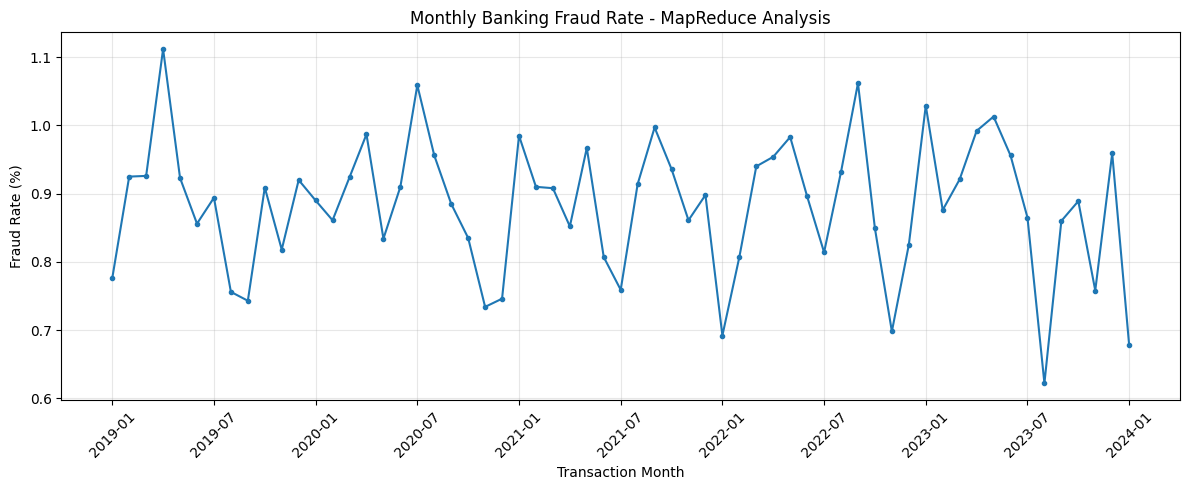


TASK 2 PART A EXECUTION COMPLETED


In [0]:

# ======================================================
# TASK 2 - PART A: MAPREDUCE AND FRAUD VISUALISATION
# ======================================================

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# STEP 1: Load cleaned banking dataset
banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

print("STEP 1: DATA LOADED")
print("Total records:", banking_df.count())


# STEP 2: MAP PHASE
mapped_df = (
    banking_df
    .select(
        F.col("transaction_month").alias("Month"),
        F.lit(1).alias("Transaction_Unit"),
        F.col("transaction_amount").alias("Amount"),
        F.when(
            F.col("is_fraud") == 1, 1
        ).otherwise(0).alias("Fraud_Unit")
    )
    .filter(
        F.col("Month").isNotNull()
        & F.col("Amount").isNotNull()
    )
)

print("\nSTEP 2: MAP PHASE")
display(mapped_df.limit(5))


# STEP 3: REDUCE PHASE
monthly_results = (
    mapped_df
    .groupBy("Month")
    .agg(
        F.sum("Transaction_Unit").alias(
            "Transaction_Count"
        ),
        F.round(F.sum("Amount"), 2).alias(
            "Total_Amount"
        ),
        F.sum("Fraud_Unit").alias(
            "Fraud_Count"
        )
    )
    .withColumn(
        "Fraud_Rate_Percent",
        F.round(
            F.col("Fraud_Count")
            / F.col("Transaction_Count") * 100,
            3
        )
    )
    .orderBy("Month")
)

print("\nSTEP 3: REDUCE PHASE")
display(monthly_results)


# STEP 4: VERIFY RESULTS
print("\nSTEP 4: RESULT VERIFICATION")

summary = monthly_results.agg(
    F.sum("Transaction_Count").alias("Total_Transactions"),
    F.sum("Fraud_Count").alias("Total_Fraud"),
    F.round(F.sum("Total_Amount"), 2).alias("Total_Amount")
)

display(summary)

input_count = banking_df.count()
aggregated_count = mapped_df.count()

print("Input transactions:", input_count)
print("Transactions analysed:", aggregated_count)

assert input_count == aggregated_count, (
    "Some transactions were excluded from the analysis."
)


# STEP 5: VISUALISE FRAUD TRENDS
print("\nSTEP 5: MONTHLY FRAUD RATE VISUALISATION")

plot_df = (
    monthly_results
    .select("Month", "Fraud_Rate_Percent")
    .orderBy("Month")
    .toPandas()
)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df["Month"],
    plot_df["Fraud_Rate_Percent"],
    marker="o",
    markersize=3
)

plt.title(
    "Monthly Banking Fraud Rate - MapReduce Analysis"
)

plt.xlabel("Transaction Month")
plt.ylabel("Fraud Rate (%)")

plt.xticks(
    range(0, len(plot_df), 6),
    plot_df["Month"].iloc[::6],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTASK 2 PART A EXECUTION COMPLETED")


In [0]:

# Show the physical execution plan
# for the distributed monthly aggregation

monthly_results.explain(mode="formatted")


== Physical Plan ==
AdaptiveSparkPlan (8)
+- == Initial Plan ==
   PhotonResultStage (7)
   +- PhotonColumnarToRow (6)
      +- PhotonSort (5)
         +- PhotonProject (4)
            +- PhotonGroupingAgg (3)
               +- PhotonProject (2)
                  +- PhotonScan parquet workspace.default.banking_transactions_clean (1)


(1) PhotonScan parquet workspace.default.banking_transactions_clean
Output [3]: [transaction_amount#10290, is_fraud#10302, transaction_month#10304]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-h7uv8/uc/e5c351fe-d753-4506-8ec4-be521341515a/be56c8df-1e13-4e21-8248-6bad31f6261e/__unitystorage/catalogs/824a43d4-9d26-4e7d-b3d5-a2fbaece93e8/tables/438bbf71-11c6-46d4-ac7b-66478aa4fce7]
ReadSchema: struct<transaction_amount:double,is_fraud:int,transaction_month:string>
RequiredDataFilters: [isnotnull(transaction_amount#10290), isnotnull(transaction_month#10304)]

(2) PhotonProject
Input [3]: [transaction_amount#10290, is_fraud#10302, transaction_month#10

In [0]:

# TASK 2 PART B - STEP 3
# Examine Spark data partitioning

from pyspark.sql import functions as F

banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

print("DATA PARTITIONING ANALYSIS")

# Identify Spark execution partitions
partition_distribution = (
    banking_df
    .withColumn(
        "Partition_ID",
        F.spark_partition_id()
    )
    .groupBy("Partition_ID")
    .count()
    .orderBy("Partition_ID")
)

display(partition_distribution)

print(
    "Total records:",
    partition_distribution.agg(
        F.sum("count")
    ).first()[0]
)

print(
    "Observed partition IDs:",
    partition_distribution.count()
)


DATA PARTITIONING ANALYSIS


Partition_ID,count
0,550000


Total records: 550000
Observed partition IDs: 1


In [0]:

# TASK 2 PART B 
# Performance comparison using different partitions

import time
from pyspark.sql import functions as F

banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

performance_results = []

for partitions in [2, 4, 8]:

    start_time = time.perf_counter()

    test_df = banking_df.repartition(partitions)

    result = (
        test_df
        .groupBy("transaction_month")
        .agg(
            F.count("*").alias("Transaction_Count"),
            F.sum("transaction_amount").alias("Total_Amount"),
            F.sum(
                F.when(F.col("is_fraud") == 1, 1)
                .otherwise(0)
            ).alias("Fraud_Count")
        )
    )

    # Trigger execution of all aggregate outputs
    rows = result.collect()

    elapsed = time.perf_counter() - start_time

    performance_results.append(
        (partitions, len(rows), round(elapsed, 3))
    )

performance_df = spark.createDataFrame(
    performance_results,
    ["Partitions", "Monthly_Groups", "Execution_Seconds"]
)

display(performance_df)


Partitions,Monthly_Groups,Execution_Seconds
2,61,1.849
4,61,1.347
8,61,1.605


In [0]:

# ==================================================
# TASK 3 - PART A
# STEP 1: LOAD AND INSPECT BANKING DATASET
# ==================================================

from pyspark.sql import functions as F

banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

print("TASK 3 - DATASET INSPECTION")
print("=" * 45)

print("Total records:", banking_df.count())
print("Total columns:", len(banking_df.columns))

print("\nDATASET SCHEMA")
banking_df.printSchema()

print("\nFRAUD CLASS DISTRIBUTION")
display(
    banking_df.groupBy("is_fraud")
    .count()
    .orderBy("is_fraud")
)

print("\nTRANSACTION DATE RANGE")
display(
    banking_df.agg(
        F.min("transaction_date").alias("Earliest_Date"),
        F.max("transaction_date").alias("Latest_Date")
    )
)

print("\nSAMPLE TRANSACTIONS")
display(banking_df.limit(5))


TASK 3 - DATASET INSPECTION
Total records: 550000
Total columns: 22

DATASET SCHEMA
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: date (nullable = true)
 |-- transaction_time: string (nullable = true)
 |-- account_type: string (nullable = true)
 |-- transaction_type: string (nullable = true)
 |-- transaction_amount: double (nullable = true)
 |-- transaction_direction: string (nullable = true)
 |-- account_balance: double (nullable = true)
 |-- merchant_category: string (nullable = true)
 |-- state: string (nullable = true)
 |-- credit_score: integer (nullable = true)
 |-- has_loan: integer (nullable = true)
 |-- loan_type: string (nullable = true)
 |-- emi_amount: double (nullable = true)
 |-- transaction_status: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- kyc_status: string (nullable = true)
 |-- is_fraud: integer (nullable = true)
 |-- transaction_hour: integer (nullable = true)
 |-- trans

is_fraud,count
0,545127
1,4873



TRANSACTION DATE RANGE


Earliest_Date,Latest_Date
2019-01-01,2024-01-01



SAMPLE TRANSACTIONS


transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,transaction_month,transaction_year
TXN000000083,CUST048191,2019-01-01,14:19,Fixed Deposit,UPI,354.34,Credit,168233.96,Travel,Delhi,661,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,14,2019-01,2019
TXN000000141,CUST044263,2019-01-01,05:55,Current,POS,10254.76,Debit,66540.19,Insurance,Punjab,874,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,5,2019-01,2019
TXN000000171,CUST007393,2019-01-01,17:12,Savings,Net_Banking,7622.13,Credit,103920.38,Retail,Maharashtra,490,0,Not Applicable,0.0,Success,POS_Terminal,Verified,0,17,2019-01,2019
TXN000000218,CUST029856,2019-01-01,19:52,Current,UPI,1796.92,Credit,3556363.05,E-Commerce,Tamil Nadu,411,0,Not Applicable,0.0,Success,Mobile_App,Verified,0,19,2019-01,2019
TXN000000244,CUST077506,2019-01-01,00:16,Savings,NEFT,54580.63,Debit,11246.28,Salary,Delhi,693,0,Not Applicable,0.0,Success,ATM,Verified,0,0,2019-01,2019


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 2: DATA PREPARATION AND FEATURE INSPECTION
# =====================================================

from pyspark.sql import functions as F

# Load the cleaned banking dataset
banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

# Create the missing transaction_day feature
banking_df = banking_df.withColumn(
    "transaction_day",
    F.dayofmonth(F.to_date("transaction_date"))
)

# Select numerical and categorical features
numeric_features = [
    "transaction_amount",
    "account_balance",
    "credit_score",
    "transaction_hour",
    "transaction_day"
]

categorical_features = [
    "account_type",
    "transaction_type",
    "transaction_direction",
    "merchant_category",
    "channel"
]

selected_columns = (
    numeric_features
    + categorical_features
    + ["transaction_date", "is_fraud"]
)

ml_df = banking_df.select(*selected_columns)

print("STEP 2: FEATURE PREPARATION")
print("Selected records:", ml_df.count())
print("Selected columns:", len(ml_df.columns))

# Check missing values
print("\nMISSING VALUE ANALYSIS")

missing_counts = ml_df.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c)
    for c in ml_df.columns
])

display(missing_counts)

# Inspect fraud class distribution
print("\nFRAUD CLASS DISTRIBUTION")

display(
    ml_df.groupBy("is_fraud")
    .count()
    .orderBy("is_fraud")
)

# Display selected features
print("\nSELECTED MACHINE LEARNING FEATURES")

display(ml_df.limit(5))


STEP 2: FEATURE PREPARATION
Selected records: 550000
Selected columns: 12

MISSING VALUE ANALYSIS


transaction_amount,account_balance,credit_score,transaction_hour,transaction_day,account_type,transaction_type,transaction_direction,merchant_category,channel,transaction_date,is_fraud
0,0,0,0,0,0,0,0,0,0,0,0



FRAUD CLASS DISTRIBUTION


is_fraud,count
0,545127
1,4873



SELECTED MACHINE LEARNING FEATURES


transaction_amount,account_balance,credit_score,transaction_hour,transaction_day,account_type,transaction_type,transaction_direction,merchant_category,channel,transaction_date,is_fraud
354.34,168233.96,661,14,1,Fixed Deposit,UPI,Credit,Travel,Mobile_App,2019-01-01,0
10254.76,66540.19,874,5,1,Current,POS,Debit,Insurance,Mobile_App,2019-01-01,0
7622.13,103920.38,490,17,1,Savings,Net_Banking,Credit,Retail,POS_Terminal,2019-01-01,0
1796.92,3556363.05,411,19,1,Current,UPI,Credit,E-Commerce,Mobile_App,2019-01-01,0
54580.63,11246.28,693,0,1,Savings,NEFT,Debit,Salary,ATM,2019-01-01,0


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 3: CHRONOLOGICAL TRAIN/TEST SPLIT
# =====================================================

from pyspark.sql import functions as F

# Reload prepared features if the notebook was restarted
if "ml_df" not in globals():
    banking_df = spark.table(
        "workspace.default.banking_transactions_clean"
    )

    ml_df = banking_df.withColumn(
        "transaction_day",
        F.dayofmonth(F.to_date("transaction_date"))
    ).select(
        "transaction_amount",
        "account_balance",
        "credit_score",
        "transaction_hour",
        "transaction_day",
        "account_type",
        "transaction_type",
        "transaction_direction",
        "merchant_category",
        "channel",
        "transaction_date",
        "is_fraud"
    )

# Convert date to a consistent DateType
ml_df = ml_df.withColumn(
    "transaction_date",
    F.to_date("transaction_date")
)

# Train: transactions before 2023
# Test: transactions from 2023 onward
train_df = ml_df.filter(
    F.col("transaction_date") < F.lit("2023-01-01")
)

test_df = ml_df.filter(
    F.col("transaction_date") >= F.lit("2023-01-01")
)

print("STEP 3: CHRONOLOGICAL DATA SPLITTING")

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("\nTRAINING FRAUD DISTRIBUTION")
display(
    train_df.groupBy("is_fraud")
    .count()
    .orderBy("is_fraud")
)

print("\nTESTING FRAUD DISTRIBUTION")
display(
    test_df.groupBy("is_fraud")
    .count()
    .orderBy("is_fraud")
)

print("\nDATE RANGE VERIFICATION")

display(
    train_df.agg(
        F.min("transaction_date").alias("Train_Start"),
        F.max("transaction_date").alias("Train_End")
    )
)

display(
    test_df.agg(
        F.min("transaction_date").alias("Test_Start"),
        F.max("transaction_date").alias("Test_End")
    )
)

# Verify that no records were lost
assert train_df.count() + test_df.count() == ml_df.count()

print("\nChronological split verified successfully.")


STEP 3: CHRONOLOGICAL DATA SPLITTING
Training records: 440121
Testing records: 109879

TRAINING FRAUD DISTRIBUTION


is_fraud,count
0,436231
1,3890



TESTING FRAUD DISTRIBUTION


is_fraud,count
0,108896
1,983



DATE RANGE VERIFICATION


Train_Start,Train_End
2019-01-01,2022-12-31


Test_Start,Test_End
2023-01-01,2024-01-01



Chronological split verified successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 4: RANDOM FOREST CLASSIFICATION TRAINING
# =====================================================

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier

numeric_features = [
    "transaction_amount",
    "account_balance",
    "credit_score",
    "transaction_hour",
    "transaction_day"
]

categorical_features = [
    "account_type",
    "transaction_type",
    "transaction_direction",
    "merchant_category",
    "channel"
]

# Encode categorical attributes
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_index",
        handleInvalid="keep"
    )
    for c in categorical_features
]

encoders = [
    OneHotEncoder(
        inputCols=[c + "_index" for c in categorical_features],
        outputCols=[c + "_encoded" for c in categorical_features],
        handleInvalid="keep"
    )
]

# Combine numerical and encoded categorical features
assembler = VectorAssembler(
    inputCols=(
        numeric_features
        + [c + "_encoded" for c in categorical_features]
    ),
    outputCol="features",
    handleInvalid="keep"
)

# Random Forest classification model
rf = RandomForestClassifier(
    labelCol="is_fraud",
    featuresCol="features",
    numTrees=50,
    maxDepth=8,
    seed=42
)

# Create ML pipeline
pipeline = Pipeline(
    stages=indexers + encoders + [assembler, rf]
)

print("STEP 4: TRAINING RANDOM FOREST CLASSIFIER")

# Train only on historical training records
rf_model = pipeline.fit(train_df)

print("Random Forest training completed successfully.")

print("Number of trees:", rf.getNumTrees())
print("Maximum tree depth:", rf.getMaxDepth())

# Generate predictions on unseen test records
rf_predictions = rf_model.transform(test_df)

print("\nTEST PREDICTIONS")
display(
    rf_predictions.select(
        "transaction_date",
        "is_fraud",
        "prediction",
        "probability"
    ).limit(10)
)


STEP 4: TRAINING RANDOM FOREST CLASSIFIER
Random Forest training completed successfully.
Number of trees: 50
Maximum tree depth: 8

TEST PREDICTIONS


transaction_date,is_fraud,prediction,probability
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9916644441703005"",""0.008335555829699472""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9914085756647016"",""0.008591424335298348""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9916341913011344"",""0.008365808698865551""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9916940698220977"",""0.00830593017790228""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9923026426187053"",""0.007697357381294644""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9920256401284832"",""0.00797435987151684""]}"
2023-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9920357355197246"",""0.00796426448027542""]}"
2023-01-02,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9889112854068028"",""0.011088714593197201""]}"
2023-01-02,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9916897706600529"",""0.00831022933994708""]}"
2023-01-02,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9914619253397396"",""0.008538074660260441""]}"


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 5: RANDOM FOREST CLASSIFICATION EVALUATION
# =====================================================

from pyspark.sql import functions as F
from pyspark.ml.evaluation import BinaryClassificationEvaluator

print("STEP 5: RANDOM FOREST MODEL EVALUATION")

# Confusion matrix counts
counts = (
    rf_predictions
    .groupBy("is_fraud", "prediction")
    .count()
    .collect()
)

cm = {
    (int(row["is_fraud"]), int(row["prediction"])): row["count"]
    for row in counts
}

TN = cm.get((0, 0), 0)
FP = cm.get((0, 1), 0)
FN = cm.get((1, 0), 0)
TP = cm.get((1, 1), 0)

print("\nCONFUSION MATRIX")
print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)

# Calculate classification metrics
accuracy = (TP + TN) / max(TP + TN + FP + FN, 1)
precision = TP / max(TP + FP, 1)
recall = TP / max(TP + FN, 1)
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

specificity = TN / max(TN + FP, 1)

print("\nCLASSIFICATION METRICS")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"Specificity: {specificity:.4f}")

# ROC-AUC and PR-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="is_fraud",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

pr_evaluator = BinaryClassificationEvaluator(
    labelCol="is_fraud",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

roc_auc = roc_evaluator.evaluate(rf_predictions)
pr_auc = pr_evaluator.evaluate(rf_predictions)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

# Display metrics table
metrics_df = spark.createDataFrame([
    ("Accuracy", float(accuracy)),
    ("Precision", float(precision)),
    ("Recall", float(recall)),
    ("F1-score", float(f1)),
    ("Specificity", float(specificity)),
    ("ROC-AUC", float(roc_auc)),
    ("PR-AUC", float(pr_auc))
], ["Metric", "Value"])

display(metrics_df)


STEP 5: RANDOM FOREST MODEL EVALUATION

CONFUSION MATRIX
True Negatives: 108896
False Positives: 0
False Negatives: 983
True Positives: 0

CLASSIFICATION METRICS
Accuracy: 0.9911
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
Specificity: 1.0000
ROC-AUC: 0.5516
PR-AUC: 0.0138


Metric,Value
Accuracy,0.991053795538729
Precision,0.0
Recall,0.0
F1-score,0.0
Specificity,1.0
ROC-AUC,0.551630706509635
PR-AUC,0.013830107317247736


In [0]:

# TASK 3 - STEP 6
# Create a chronological validation dataset

from pyspark.sql import functions as F

train_inner_df = train_df.filter(
    F.col("transaction_date") < F.lit("2022-01-01")
)

validation_df = train_df.filter(
    F.col("transaction_date") >= F.lit("2022-01-01")
)

print("Training records:", train_inner_df.count())
print("Validation records:", validation_df.count())
print("Final test records:", test_df.count())

print("\nVALIDATION FRAUD DISTRIBUTION")
display(
    validation_df.groupBy("is_fraud")
    .count()
    .orderBy("is_fraud")
)

print("\nCHRONOLOGICAL SPLIT VERIFICATION")
assert (
    train_inner_df.count() + validation_df.count()
    == train_df.count()
)

print("Validation split completed successfully.")


Training records: 329874
Validation records: 110247
Final test records: 109879

VALIDATION FRAUD DISTRIBUTION


is_fraud,count
0,109287
1,960



CHRONOLOGICAL SPLIT VERIFICATION
Validation split completed successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 7: RETRAIN RANDOM FOREST FOR VALIDATION
# =====================================================

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer, OneHotEncoder, VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier
from pyspark.sql import functions as F

numeric_features = [
    "transaction_amount",
    "account_balance",
    "credit_score",
    "transaction_hour",
    "transaction_day"
]

categorical_features = [
    "account_type",
    "transaction_type",
    "transaction_direction",
    "merchant_category",
    "channel"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_index",
        handleInvalid="keep"
    )
    for c in categorical_features
]

encoder = OneHotEncoder(
    inputCols=[c + "_index" for c in categorical_features],
    outputCols=[c + "_encoded" for c in categorical_features],
    handleInvalid="keep"
)

assembler = VectorAssembler(
    inputCols=numeric_features + [
        c + "_encoded" for c in categorical_features
    ],
    outputCol="features",
    handleInvalid="keep"
)

rf_tuned = RandomForestClassifier(
    labelCol="is_fraud",
    featuresCol="features",
    numTrees=100,
    maxDepth=10,
    seed=42
)

tuned_pipeline = Pipeline(
    stages=indexers + [encoder, assembler, rf_tuned]
)

print("STEP 7: TRAINING IMPROVED RANDOM FOREST")

validation_model = tuned_pipeline.fit(train_inner_df)

print("Training completed.")
print("Number of trees:", rf_tuned.getNumTrees())
print("Maximum depth:", rf_tuned.getMaxDepth())

validation_predictions = validation_model.transform(
    validation_df
)

print("\nVALIDATION PREDICTIONS")
display(
    validation_predictions.select(
        "transaction_date",
        "is_fraud",
        "prediction",
        "probability"
    ).limit(10)
)


STEP 7: TRAINING IMPROVED RANDOM FOREST
Training completed.
Number of trees: 100
Maximum depth: 10

VALIDATION PREDICTIONS


transaction_date,is_fraud,prediction,probability
2022-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9915743796700188"",""0.00842562032998119""]}"
2022-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9919032868151629"",""0.008096713184837082""]}"
2022-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9920487360559581"",""0.007951263944041984""]}"
2022-01-01,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9784353231177718"",""0.02156467688222815""]}"
2022-01-02,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9917252665270386"",""0.008274733472961348""]}"
2022-01-03,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9916963340013365"",""0.008303665998663499""]}"
2022-01-03,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9922014397086225"",""0.007798560291377512""]}"
2022-01-04,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.991794157844416"",""0.008205842155583948""]}"
2022-01-04,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9913729086178437"",""0.008627091382156359""]}"
2022-01-04,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9915032976018087"",""0.008496702398191301""]}"


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 8: FRAUD PROBABILITY THRESHOLD OPTIMISATION
# =====================================================

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Extract probability of fraud (class 1)
validation_scored = validation_predictions.withColumn(
    "Fraud_Probability",
    vector_to_array(F.col("probability"))[1]
).select("is_fraud", "Fraud_Probability")

thresholds = [0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.10, 0.20, 0.50]

# Evaluate thresholds on validation data
results = []

for threshold in thresholds:
    pred = validation_scored.withColumn(
        "Predicted_Fraud",
        F.when(
            F.col("Fraud_Probability") >= threshold, 1
        ).otherwise(0)
    )

    counts = pred.agg(
        F.sum(F.when(
            (F.col("is_fraud") == 1) &
            (F.col("Predicted_Fraud") == 1), 1
        ).otherwise(0)).alias("TP"),

        F.sum(F.when(
            (F.col("is_fraud") == 0) &
            (F.col("Predicted_Fraud") == 1), 1
        ).otherwise(0)).alias("FP"),

        F.sum(F.when(
            (F.col("is_fraud") == 1) &
            (F.col("Predicted_Fraud") == 0), 1
        ).otherwise(0)).alias("FN")
    ).first()

    tp = counts["TP"]
    fp = counts["FP"]
    fn = counts["FN"]

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    results.append((
        float(threshold),
        int(tp),
        int(fp),
        int(fn),
        float(precision),
        float(recall),
        float(f1)
    ))

threshold_df = spark.createDataFrame(
    results,
    [
        "Threshold",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "F1_Score"
    ]
)

print("STEP 8: VALIDATION THRESHOLD COMPARISON")
display(threshold_df.orderBy("Threshold"))

# Select threshold using validation F1-score
best_row = threshold_df.orderBy(
    F.desc("F1_Score"),
    F.desc("Precision"),
    F.desc("Threshold")
).first()

best_threshold = float(best_row["Threshold"])

print("\nBEST VALIDATION THRESHOLD:", best_threshold)
print("BEST VALIDATION F1:", round(best_row["F1_Score"], 4))
print("VALIDATION PRECISION:", round(best_row["Precision"], 4))
print("VALIDATION RECALL:", round(best_row["Recall"], 4))


STEP 8: VALIDATION THRESHOLD COMPARISON


Threshold,TP,FP,FN,Precision,Recall,F1_Score
0.005,960,109287,0,0.008707719937957496,1.0,0.017265100218511426
0.01,146,6945,814,0.020589479622056126,0.15208333333333332,0.03626878648615079
0.015,124,3834,836,0.031328954017180395,0.12916666666666668,0.05042700284668565
0.02,107,2812,853,0.03665638917437478,0.11145833333333334,0.05516885795308068
0.03,35,844,925,0.03981797497155859,0.036458333333333336,0.03806416530723219
0.05,6,64,954,0.08571428571428572,0.00625,0.011650485436893204
0.1,0,0,960,0.0,0.0,0.0
0.2,0,0,960,0.0,0.0,0.0
0.5,0,0,960,0.0,0.0,0.0



BEST VALIDATION THRESHOLD: 0.02
BEST VALIDATION F1: 0.0552
VALIDATION PRECISION: 0.0367
VALIDATION RECALL: 0.1115


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 9: FINAL RANDOM FOREST TEST EVALUATION
# =====================================================

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Refit the selected model on the full training period
final_rf_model = tuned_pipeline.fit(train_df)

# Predict on the untouched test period
final_predictions = final_rf_model.transform(test_df)

# Apply the threshold chosen using validation data
final_scored = (
    final_predictions
    .withColumn(
        "Fraud_Probability",
        vector_to_array(F.col("probability"))[1]
    )
    .withColumn(
        "Adjusted_Prediction",
        F.when(
            F.col("Fraud_Probability") >= best_threshold,
            1
        ).otherwise(0)
    )
)

# Confusion matrix
counts = (
    final_scored
    .groupBy("is_fraud", "Adjusted_Prediction")
    .count()
    .collect()
)

cm = {
    (int(r["is_fraud"]), int(r["Adjusted_Prediction"])): r["count"]
    for r in counts
}

TN = cm.get((0, 0), 0)
FP = cm.get((0, 1), 0)
FN = cm.get((1, 0), 0)
TP = cm.get((1, 1), 0)

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (TP + TN) / (TP + TN + FP + FN)

# Ranking metrics
roc_auc = BinaryClassificationEvaluator(
    labelCol="is_fraud",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(final_predictions)

pr_auc = BinaryClassificationEvaluator(
    labelCol="is_fraud",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
).evaluate(final_predictions)

print("STEP 9: FINAL TEST EVALUATION")
print("Selected threshold:", best_threshold)

print("\nCONFUSION MATRIX")
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

print("\nFINAL CLASSIFICATION METRICS")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

final_metrics_df = spark.createDataFrame(
    [
        ("Accuracy", float(accuracy)),
        ("Precision", float(precision)),
        ("Recall", float(recall)),
        ("F1-score", float(f1)),
        ("ROC-AUC", float(roc_auc)),
        ("PR-AUC", float(pr_auc))
    ],
    ["Metric", "Value"]
)

display(final_metrics_df)


STEP 9: FINAL TEST EVALUATION
Selected threshold: 0.02

CONFUSION MATRIX
TN: 105845
FP: 3051
FN: 874
TP: 109

FINAL CLASSIFICATION METRICS
Accuracy: 0.9643
Precision: 0.0345
Recall: 0.1109
F1-score: 0.0526
ROC-AUC: 0.5353
PR-AUC: 0.0143


Metric,Value
Accuracy,0.964278888595637
Precision,0.03449367088607595
Recall,0.11088504577822991
F1-score,0.05261887521119962
ROC-AUC,0.5353221560534372
PR-AUC,0.014308210856466061


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 10: MONTHLY TIME SERIES DATA PREPARATION
# =====================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Reload the cleaned banking dataset
banking_df = spark.table(
    "workspace.default.banking_transactions_clean"
)

# Aggregate transactions by month
monthly_ts = (
    banking_df
    .withColumn(
        "Month_Date",
        F.to_date(
            F.date_trunc(
                "month",
                F.to_date("transaction_date")
            )
        )
    )
    .groupBy("Month_Date")
    .agg(
        F.count("*").alias("Transaction_Count")
    )
    .orderBy("Month_Date")
)

print("STEP 10: MONTHLY TIME SERIES PREPARATION")
print("Number of monthly observations:", monthly_ts.count())

print("\nMONTHLY TRANSACTION DATA")
display(monthly_ts)

# Create lag-based forecasting features
window_spec = Window.orderBy("Month_Date")

forecast_df = (
    monthly_ts
    .withColumn(
        "Lag_1",
        F.lag("Transaction_Count", 1).over(window_spec)
    )
    .withColumn(
        "Lag_2",
        F.lag("Transaction_Count", 2).over(window_spec)
    )
    .withColumn(
        "Lag_3",
        F.lag("Transaction_Count", 3).over(window_spec)
    )
    .withColumn(
        "Month_Number",
        F.month("Month_Date")
    )
    .dropna()
)

print("\nFORECASTING FEATURES")
display(forecast_df)

print(
    "\nForecasting observations:",
    forecast_df.count()
)


STEP 10: MONTHLY TIME SERIES PREPARATION
Number of monthly observations: 61

MONTHLY TRANSACTION DATA


Month_Date,Transaction_Count
2019-01-01,9406
2019-02-01,8220
2019-03-01,9290
2019-04-01,8990
2019-05-01,9425
2019-06-01,9107
2019-07-01,9400
2019-08-01,9524
2019-09-01,8877
2019-10-01,9576



FORECASTING FEATURES


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Month_Date,Transaction_Count,Lag_1,Lag_2,Lag_3,Month_Number
2019-04-01,8990,9290,8220,9406,4
2019-05-01,9425,8990,9290,8220,5
2019-06-01,9107,9425,8990,9290,6
2019-07-01,9400,9107,9425,8990,7
2019-08-01,9524,9400,9107,9425,8
2019-09-01,8877,9524,9400,9107,9
2019-10-01,9576,8877,9524,9400,10
2019-11-01,8922,9576,8877,9524,11
2019-12-01,9346,8922,9576,8877,12
2020-01-01,9440,9346,8922,9576,1



Forecasting observations: 58


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 11: TIME SERIES TRAIN/TEST SPLIT
# =====================================================

from pyspark.sql import functions as F

# Exclude incomplete January 2024
forecast_complete = forecast_df.filter(
    F.col("Month_Date") < F.lit("2024-01-01")
)

# Chronological training split
forecast_train = forecast_complete.filter(
    F.col("Month_Date") < F.lit("2023-01-01")
)

# Chronological testing split
forecast_test = forecast_complete.filter(
    (F.col("Month_Date") >= F.lit("2023-01-01"))
    & (F.col("Month_Date") < F.lit("2024-01-01"))
)

print("STEP 11: TIME SERIES TRAIN/TEST SPLIT")

print("Training observations:", forecast_train.count())
print("Testing observations:", forecast_test.count())

print("\nTRAINING DATE RANGE")
display(
    forecast_train.agg(
        F.min("Month_Date").alias("Train_Start"),
        F.max("Month_Date").alias("Train_End")
    )
)

print("\nTESTING DATE RANGE")
display(
    forecast_test.agg(
        F.min("Month_Date").alias("Test_Start"),
        F.max("Month_Date").alias("Test_End")
    )
)

print("\nTESTING DATA WITH LAG FEATURES")
display(forecast_test.orderBy("Month_Date"))

assert (
    forecast_train.count() + forecast_test.count()
    == forecast_complete.count()
)

print("\nTime series split verified successfully.")


STEP 11: TIME SERIES TRAIN/TEST SPLIT


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Training observations: 45
Testing observations: 12

TRAINING DATE RANGE


Train_Start,Train_End
2019-04-01,2022-12-01



TESTING DATE RANGE


Test_Start,Test_End
2023-01-01,2023-12-01



TESTING DATA WITH LAG FEATURES


Month_Date,Transaction_Count,Lag_1,Lag_2,Lag_3,Month_Number
2023-01-01,9332,9210,9316,9307,1
2023-02-01,8338,9332,9210,9316,2
2023-03-01,9225,8338,9332,9210,3
2023-04-01,8973,9225,8338,9332,4
2023-05-01,9278,8973,9225,8338,5
2023-06-01,9098,9278,8973,9225,6
2023-07-01,9481,9098,9278,8973,7
2023-08-01,9323,9481,9098,9278,8
2023-09-01,8956,9323,9481,9098,9
2023-10-01,9334,8956,9323,9481,10



Time series split verified successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 12: RANDOM FOREST TIME SERIES FORECASTING
# =====================================================

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

print("STEP 12: RANDOM FOREST REGRESSION FORECASTING")

# Define forecasting input features
forecast_features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Month_Number"
]

# Assemble features
forecast_assembler = VectorAssembler(
    inputCols=forecast_features,
    outputCol="features"
)

# Define regression model
forecast_rf = RandomForestRegressor(
    labelCol="Transaction_Count",
    featuresCol="features",
    numTrees=100,
    maxDepth=5,
    seed=42
)

# Create forecasting pipeline
forecast_pipeline = Pipeline(
    stages=[
        forecast_assembler,
        forecast_rf
    ]
)

# Train on historical months
forecast_model = forecast_pipeline.fit(forecast_train)

print("Random Forest Regression training completed.")
print("Number of trees:", forecast_rf.getNumTrees())
print("Maximum depth:", forecast_rf.getMaxDepth())

# Predict the 2023 monthly transaction counts
forecast_predictions = forecast_model.transform(
    forecast_test
)

# Add simple lag-1 baseline predictions
forecast_predictions = forecast_predictions.withColumn(
    "Baseline_Prediction",
    F.col("Lag_1").cast("double")
)

print("\nACTUAL VS PREDICTED MONTHLY TRANSACTIONS")

display(
    forecast_predictions.select(
        "Month_Date",
        "Transaction_Count",
        F.round("prediction", 2).alias("RF_Prediction"),
        "Baseline_Prediction"
    ).orderBy("Month_Date")
)

# Evaluate Random Forest and baseline
def calculate_metrics(df, prediction_col):
    evaluator_mae = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol=prediction_col,
        metricName="mae"
    )

    evaluator_rmse = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol=prediction_col,
        metricName="rmse"
    )

    mae = evaluator_mae.evaluate(df)
    rmse = evaluator_rmse.evaluate(df)

    mape = df.select(
        F.avg(
            F.abs(
                (F.col("Transaction_Count") -
                 F.col(prediction_col)) /
                F.col("Transaction_Count")
            )
        ).alias("MAPE")
    ).first()["MAPE"] * 100

    return mae, rmse, mape

rf_mae, rf_rmse, rf_mape = calculate_metrics(
    forecast_predictions,
    "prediction"
)

base_mae, base_rmse, base_mape = calculate_metrics(
    forecast_predictions,
    "Baseline_Prediction"
)

print("\nFORECASTING MODEL PERFORMANCE")

comparison_df = spark.createDataFrame([
    ("Random Forest Regression", rf_mae, rf_rmse, rf_mape),
    ("Lag-1 Baseline", base_mae, base_rmse, base_mape)
], ["Model", "MAE", "RMSE", "MAPE_Percent"])

display(comparison_df)

print("\nStep 12 completed successfully.")


STEP 12: RANDOM FOREST REGRESSION FORECASTING


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Random Forest Regression training completed.
Number of trees: 100
Maximum depth: 5

ACTUAL VS PREDICTED MONTHLY TRANSACTIONS


Month_Date,Transaction_Count,RF_Prediction,Baseline_Prediction
2023-01-01,9332,9178.91,9210.0
2023-02-01,8338,9015.14,9332.0
2023-03-01,9225,9269.16,8338.0
2023-04-01,8973,9039.89,9225.0
2023-05-01,9278,9346.69,8973.0
2023-06-01,9098,9184.74,9278.0
2023-07-01,9481,9261.17,9098.0
2023-08-01,9323,9229.71,9481.0
2023-09-01,8956,9150.07,9323.0
2023-10-01,9334,9327.88,8956.0



FORECASTING MODEL PERFORMANCE


Model,MAE,RMSE,MAPE_Percent
Random Forest Regression,156.20742320831354,234.65276062731647,1.764699738076145
Lag-1 Baseline,391.3333333333333,470.28147599779714,4.346398251289188



Step 12 completed successfully.


STEP 13: FORECASTING VISUALISATION


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


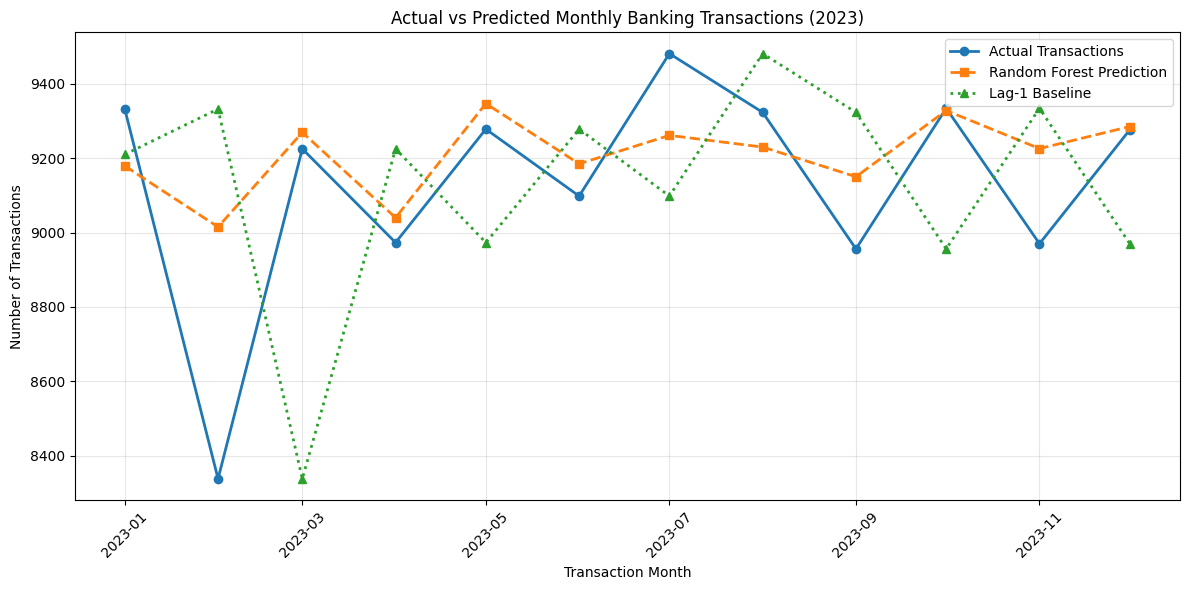

Step 13 completed successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 13: ACTUAL VS PREDICTED FORECAST VISUALISATION
# =====================================================

import matplotlib.pyplot as plt
import pandas as pd

print("STEP 13: FORECASTING VISUALISATION")

# Collect only the 12 monthly test observations
plot_pdf = (
    forecast_predictions
    .select(
        "Month_Date",
        "Transaction_Count",
        "prediction",
        "Baseline_Prediction"
    )
    .orderBy("Month_Date")
    .toPandas()
)

plot_pdf["Month_Date"] = pd.to_datetime(
    plot_pdf["Month_Date"]
)

plt.figure(figsize=(12, 6))

plt.plot(
    plot_pdf["Month_Date"],
    plot_pdf["Transaction_Count"],
    marker="o",
    linewidth=2,
    label="Actual Transactions"
)

plt.plot(
    plot_pdf["Month_Date"],
    plot_pdf["prediction"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Random Forest Prediction"
)

plt.plot(
    plot_pdf["Month_Date"],
    plot_pdf["Baseline_Prediction"],
    marker="^",
    linestyle=":",
    linewidth=2,
    label="Lag-1 Baseline"
)

plt.title(
    "Actual vs Predicted Monthly Banking Transactions (2023)"
)

plt.xlabel("Transaction Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Step 13 completed successfully.")


STEP 14: FORECASTING FEATURE IMPORTANCE

FEATURE IMPORTANCE RESULTS
     Feature  Importance
       Lag_1    0.292037
Month_Number    0.279920
       Lag_3    0.221163
       Lag_2    0.206880


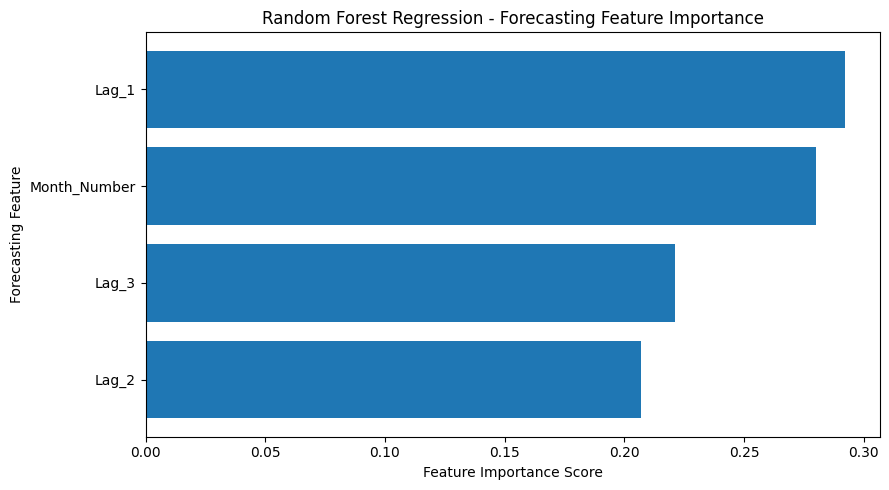


Step 14 completed successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 14: RANDOM FOREST FEATURE IMPORTANCE
# =====================================================

import matplotlib.pyplot as plt
import pandas as pd

print("STEP 14: FORECASTING FEATURE IMPORTANCE")

# Extract trained Random Forest Regression model
trained_rf = forecast_model.stages[-1]

# Get feature importance values
importance_values = trained_rf.featureImportances.toArray()

feature_names = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Month_Number"
]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE RESULTS")
print(importance_df.to_string(index=False))

# Visualise feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()

plt.title(
    "Random Forest Regression - Forecasting Feature Importance"
)

plt.xlabel("Feature Importance Score")
plt.ylabel("Forecasting Feature")

plt.tight_layout()
plt.show()

print("\nStep 14 completed successfully.")


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 15: FORECASTING HYPERPARAMETER COMPARISON
# =====================================================

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

print("STEP 15: FORECASTING HYPERPARAMETER COMPARISON")

# Create chronological training and validation datasets
forecast_train_inner = forecast_train.filter(
    F.col("Month_Date") < F.lit("2022-01-01")
)

forecast_validation = forecast_train.filter(
    F.col("Month_Date") >= F.lit("2022-01-01")
)

print("Training months:", forecast_train_inner.count())
print("Validation months:", forecast_validation.count())
print("Final test months:", forecast_test.count())

# Compare selected configurations
configurations = [
    (50, 3),
    (50, 5),
    (100, 3),
    (100, 5),
    (150, 5)
]

results = []

for num_trees, max_depth in configurations:

    assembler = VectorAssembler(
        inputCols=[
            "Lag_1",
            "Lag_2",
            "Lag_3",
            "Month_Number"
        ],
        outputCol="features"
    )

    regressor = RandomForestRegressor(
        labelCol="Transaction_Count",
        featuresCol="features",
        numTrees=num_trees,
        maxDepth=max_depth,
        seed=42
    )

    pipeline = Pipeline(
        stages=[assembler, regressor]
    )

    model = pipeline.fit(forecast_train_inner)
    predictions = model.transform(forecast_validation)

    mae = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol="prediction",
        metricName="mae"
    ).evaluate(predictions)

    rmse = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol="prediction",
        metricName="rmse"
    ).evaluate(predictions)

    results.append((
        int(num_trees),
        int(max_depth),
        float(mae),
        float(rmse)
    ))

tuning_df = spark.createDataFrame(
    results,
    [
        "Num_Trees",
        "Max_Depth",
        "Validation_MAE",
        "Validation_RMSE"
    ]
)

print("\nHYPERPARAMETER COMPARISON RESULTS")
display(tuning_df.orderBy("Validation_MAE"))

# Select best configuration using validation MAE
best_config = tuning_df.orderBy(
    "Validation_MAE",
    "Validation_RMSE"
).first()

print("\nBEST VALIDATION CONFIGURATION")
print("Number of trees:", best_config["Num_Trees"])
print("Maximum depth:", best_config["Max_Depth"])
print("Validation MAE:", round(best_config["Validation_MAE"], 2))
print("Validation RMSE:", round(best_config["Validation_RMSE"], 2))

print("\nStep 15 completed successfully.")


STEP 15: FORECASTING HYPERPARAMETER COMPARISON


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Training months: 33
Validation months: 12
Final test months: 12

HYPERPARAMETER COMPARISON RESULTS


Num_Trees,Max_Depth,Validation_MAE,Validation_RMSE
150,5,156.00302683386462,257.4359964028288
50,5,159.78188834776347,259.6554054406819
100,3,159.89447393235682,267.7158920219594
50,3,162.738024147873,266.66105517629245
100,5,166.07285917729374,270.403852596371



BEST VALIDATION CONFIGURATION
Number of trees: 150
Maximum depth: 5
Validation MAE: 156.0
Validation RMSE: 257.44

Step 15 completed successfully.


In [0]:

# =====================================================
# TASK 3 - PART A
# STEP 16: FINAL OPTIMISED FORECASTING EVALUATION
# =====================================================

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

print("STEP 16: FINAL OPTIMISED FORECASTING MODEL")

# Use hyperparameters selected on validation data
best_trees = int(best_config["Num_Trees"])
best_depth = int(best_config["Max_Depth"])

assembler_final = VectorAssembler(
    inputCols=[
        "Lag_1",
        "Lag_2",
        "Lag_3",
        "Month_Number"
    ],
    outputCol="features"
)

rf_final = RandomForestRegressor(
    labelCol="Transaction_Count",
    featuresCol="features",
    numTrees=best_trees,
    maxDepth=best_depth,
    seed=42
)

final_pipeline = Pipeline(
    stages=[assembler_final, rf_final]
)

# Retrain using all historical training observations
final_forecast_model = final_pipeline.fit(forecast_train)

# Evaluate on 2023 test observations
final_forecast_predictions = final_forecast_model.transform(
    forecast_test
)

# Add Lag-1 baseline
final_forecast_predictions = final_forecast_predictions.withColumn(
    "Baseline_Prediction",
    F.col("Lag_1").cast("double")
)

def get_forecast_metrics(df, pred_col):

    mae = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol=pred_col,
        metricName="mae"
    ).evaluate(df)

    rmse = RegressionEvaluator(
        labelCol="Transaction_Count",
        predictionCol=pred_col,
        metricName="rmse"
    ).evaluate(df)

    mape = df.select(
        F.avg(
            F.abs(
                (F.col("Transaction_Count") -
                 F.col(pred_col)) /
                F.col("Transaction_Count")
            )
        ).alias("MAPE")
    ).first()["MAPE"] * 100

    return float(mae), float(rmse), float(mape)

# Final optimised model
opt_mae, opt_rmse, opt_mape = get_forecast_metrics(
    final_forecast_predictions,
    "prediction"
)

# Original Random Forest model from Step 12
orig_mae, orig_rmse, orig_mape = get_forecast_metrics(
    forecast_predictions,
    "prediction"
)

# Lag-1 baseline
base_mae, base_rmse, base_mape = get_forecast_metrics(
    final_forecast_predictions,
    "Baseline_Prediction"
)

final_comparison = spark.createDataFrame(
    [
        ("Original RF (100 trees, depth 5)",
         orig_mae, orig_rmse, orig_mape),
        ("Optimised RF",
         opt_mae, opt_rmse, opt_mape),
        ("Lag-1 Baseline",
         base_mae, base_rmse, base_mape)
    ],
    ["Model", "MAE", "RMSE", "MAPE_Percent"]
)

print("Selected number of trees:", best_trees)
print("Selected maximum depth:", best_depth)

print("\nFINAL FORECASTING MODEL COMPARISON")
display(final_comparison)

print("\nACTUAL VS OPTIMISED PREDICTIONS")
display(
    final_forecast_predictions.select(
        "Month_Date",
        "Transaction_Count",
        F.round("prediction", 2).alias("Optimised_Prediction"),
        "Baseline_Prediction"
    ).orderBy("Month_Date")
)

print("\nStep 16 completed successfully.")


STEP 16: FINAL OPTIMISED FORECASTING MODEL


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Selected number of trees: 150
Selected maximum depth: 5

FINAL FORECASTING MODEL COMPARISON


Model,MAE,RMSE,MAPE_Percent
"Original RF (100 trees, depth 5)",156.20742320831354,234.65276062731647,1.764699738076145
Optimised RF,154.84221199358976,229.14518859634023,1.7433165073594448
Lag-1 Baseline,391.3333333333333,470.28147599779714,4.346398251289188



ACTUAL VS OPTIMISED PREDICTIONS


Month_Date,Transaction_Count,Optimised_Prediction,Baseline_Prediction
2023-01-01,9332,9073.75,9210.0
2023-02-01,8338,8984.75,9332.0
2023-03-01,9225,9260.64,8338.0
2023-04-01,8973,9040.35,9225.0
2023-05-01,9278,9344.83,8973.0
2023-06-01,9098,9139.51,9278.0
2023-07-01,9481,9273.53,9098.0
2023-08-01,9323,9200.0,9481.0
2023-09-01,8956,9104.19,9323.0
2023-10-01,9334,9340.77,8956.0



Step 16 completed successfully.
